<a href="https://colab.research.google.com/github/anashenkonina-collab/python_for_ds_task/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22HW_11_2_%D0%92%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%B4%D0%B0%D0%BD%D0%B8%D1%85_%D0%B7_Matplotlib_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Візуалізація даних з Matplotlib

## Опис завдання
У цьому домашньому завданні ви продовжите працювати з датасетом про оренду велосипедів `yulu_rental.csv`, але тепер будете використовувати бібліотеку Matplotlib для створення більш складних та налаштованих візуалізацій.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---


🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Завантаження даних
df = pd.read_csv('yulu_rental.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додаткові колонки
df['month'] = df.index.month
df['hour'] = df.index.hour
df['weekday'] = df.index.day_name()
df['weekday_num'] = df.index.weekday
df['week'] = df.index.isocalendar().week
df['year'] = df.index.year
df['day'] = df.index.day

## Завдання 1: Порівняння Pandas vs Matplotlib

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно впродовж всього періоду в даних двома способами:
1. Використовуючи Pandas (DataFrame.plot())
2. Використовуючи Matplotlib безпосередньо

В обох методах додайте маркери-кружечки. Можна також задати свій відмінний від стандартного колір.

Підказка: отримати потрібний формат даних найзручніше з методом датафрейму `resample`.

**Опишіть свої спостереження:** чим відрізняються 2 побудованих графіки? Який вам більше подобається?

In [7]:
monthly_data = df['count'].resample('M').mean()

print(monthly_data);

datetime
2011-01-31     54.645012
2011-02-28     73.641256
2011-03-31     86.849776
2011-04-30    111.026374
2011-05-31    174.809211
2011-06-30    196.877193
2011-07-31    203.614035
2011-08-31    182.666667
2011-09-30    174.622517
2011-10-31    174.773626
2011-11-30    155.458333
2011-12-31    134.173246
2012-01-31    124.353201
2012-02-29    145.646154
2012-03-31    208.276923
2012-04-30    257.455947
2012-05-31    264.109649
2012-06-30    287.186404
2012-07-31    267.037281
2012-08-31    285.570175
2012-09-30    292.598684
2012-10-31    280.508772
2012-11-30    231.980220
2012-12-31    217.054825
Freq: ME, Name: count, dtype: float64


/tmp/ipykernel_2642/1489633296.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_data = df['count'].resample('M').mean()


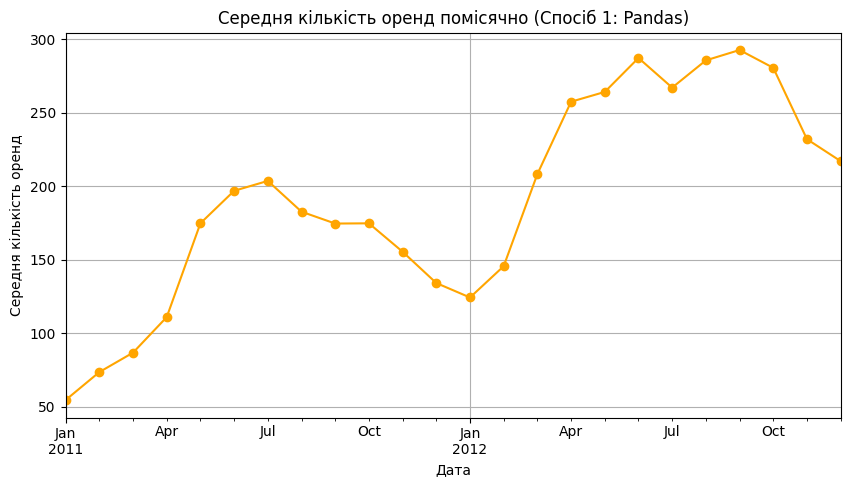

In [16]:
monthly_data.plot(kind='line', marker='o', color='orange', grid=True , figsize=(10, 5))

plt.title('Середня кількість оренд помісячно (Спосіб 1: Pandas)')
plt.xlabel('Дата')
plt.ylabel('Середня кількість оренд')

plt.show()

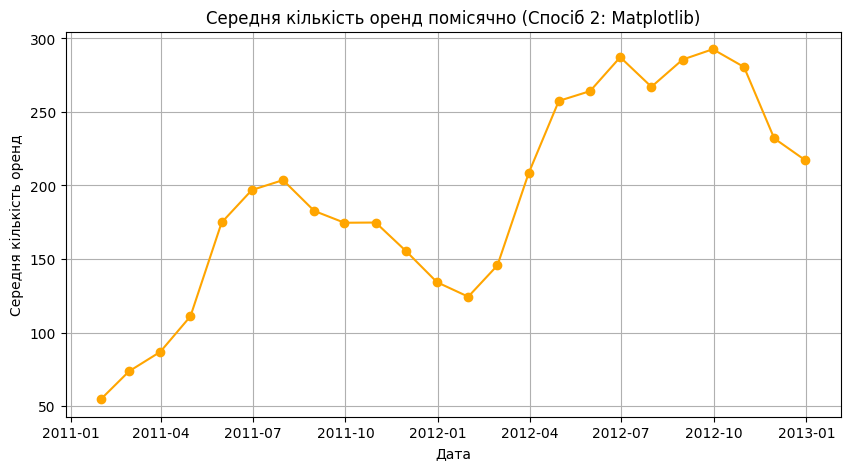

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_data.index, monthly_data.values, marker='o', color='orange', linestyle='-')

plt.grid(True)
plt.title('Середня кількість оренд помісячно (Спосіб 2: Matplotlib)')
plt.xlabel('Дата')
plt.ylabel('Середня кількість оренд')

plt.show()


У Pandas ми викликаємо метод .plot()безпосередньо з DataFrame. Це швидкий спосіб побудови базового графіка. І базовий графік може бути доповнений деталями з Matplotlib.

У Matplotlib ми самостійно створюємо полотно plt.figure(), окремо додаємо кожний елемент (заголовок, підписи, сітку). Більше кроків, але і більше контролю

## Завдання 2: Робота зі списками та numpy

**Завдання:**
Вам задані 3 списки:
1. Номер дня тижня.
2. Продажі в тиждень 1.
3. Продажі в тиждень 2.

Створіть графік, на якому лінійними графіками різних кольорів накладено продажі за обидва тижні.

Обовʼязково додайте назву графіку, підписи вісям ОХ, ОУ, назви кожного з рядів даних, легенду.

**Дайте відповіді на питання**
1. Судячи з графіку, в який тиждень проодажі були стабільніше?
2. Чи можете ви підкріпити свій висновок обчисленнями? Якими саме? Можна (але не обовʼязково) навести ці обчислення.

In [17]:
# Дані у вигляді списків
days = [1, 2, 3, 4, 5, 6, 7] # 1 - це понеділок
sales_week1 = [1349,1562,1600,1606,1510,959,822]  # Продажі за тиждень1
sales_week2 = [1321,1263,1162,1406,1421,1248,1204]  # Продажі за тиждень1

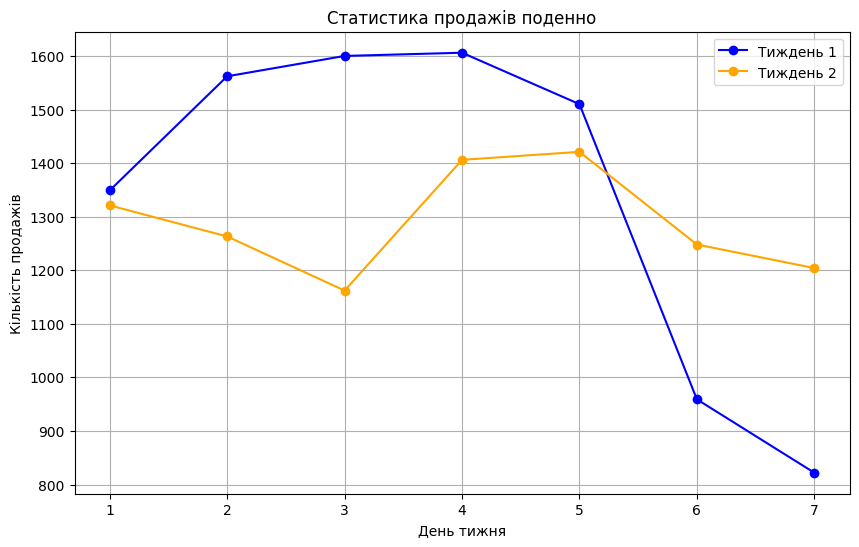

In [27]:
plt.figure(figsize=(10, 6))
plt.plot(days, sales_week1, marker='o', label='Тиждень 1', color='blue')
plt.plot(days, sales_week2, marker='o', label='Тиждень 2', color='orange')

plt.title('Статистика продажів поденно')
plt.xlabel('День тижня')
plt.ylabel('Кількість продажів')
plt.grid(True)
plt.legend()
plt.show()

Судячи з графіка, Тиждень 2 був значно стабільнішим , ніж Тиждень 1.

In [28]:
import numpy as np

std_week1 = np.std(sales_week1)
std_week2 = np.std(sales_week2)

print(f"Стандартне відхилення для Тижня 1: {std_week1:.2f}")
print(f"Стандартне відхилення для Тижня 2: {std_week2:.2f}")

Стандартне відхилення для Тижня 1: 300.00
Стандартне відхилення для Тижня 2: 90.91


Тиждень 2 - стандартне відхилення має менше значення, це означає, що продажі в цей тиждень були стабільніші

## Завдання 3: Subplot - 2x2 сітка графіків

**Завдання:**
Створіть сітку 2x2 з чотирма різними графіками, використовуючи `plt.subplot()`:
1. Лінійний графік середньої температури помісячно.
2. Стовпчикова діаграма середньої годинної кількості оренд за кварталами.
3. Гістограма вологості за всіма погодинними вимірами.
4. Scatter plot температури vs кількості оренд.

Кожен підграфік має містити всі необхідні підписи. Дашборд має містити назву.

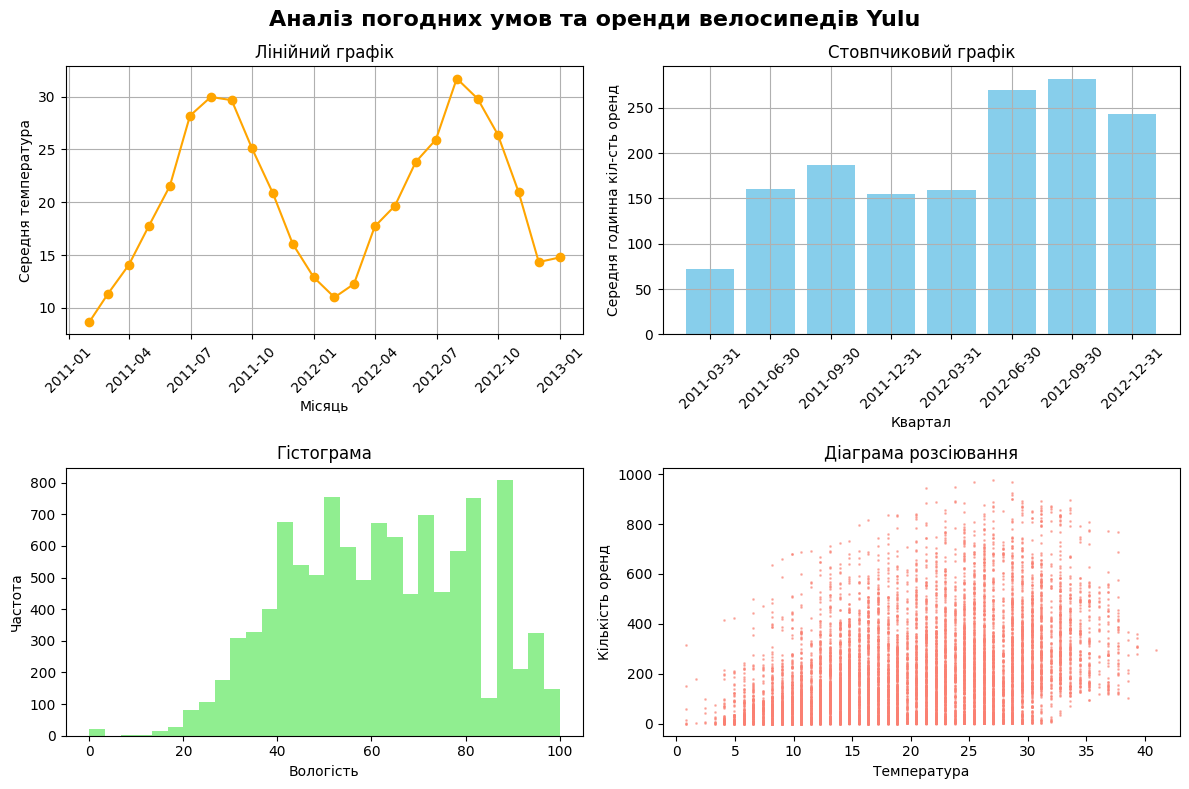

In [56]:
temp_mean = df['temp'].resample('ME').mean()
rentals_mean = df['count'].resample('QE').mean()

plt.figure(figsize=(12, 8))

# Лінійний графік
plt.subplot(2, 2, 1)
plt.plot(temp_mean.index, temp_mean.values, marker='o', color='orange', linestyle='-')
plt.title('Лінійний графік')
plt.xlabel('Місяць')
plt.ylabel('Середня температура')
plt.xticks(rotation=45)
plt.grid(True)

# Стовпчиковий графік
plt.subplot(2, 2, 2)
plt.bar(rentals_mean.index.astype(str), rentals_mean.values, color='skyblue')
plt.title('Стовпчиковий графік')
plt.xlabel('Квартал')
plt.ylabel('Середня годинна кіл-сть оренд')
plt.xticks(rotation=45)
plt.grid(True)

# Гістограма
plt.subplot(2, 2, 3)
plt.hist(df['humidity'], bins=30, color='lightgreen')
plt.title('Гістограма')
plt.xlabel('Вологість')
plt.ylabel('Частота')

# Діаграма розсіювання
plt.subplot(2, 2, 4)
plt.scatter(df['temp'], df['count'], alpha=0.5, color='salmon', s=1)
plt.title('Діаграма розсіювання')
plt.xlabel('Температура')
plt.ylabel('Кількість оренд')

plt.suptitle('Аналіз погодних умов та оренди велосипедів Yulu', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('my_dashboard.png', dpi=300);



## Завдання 4: Subplots - об'єктно-орієнтований підхід

**Завдання:**
Створіть той самий набір графіків, але використовуючи `fig, ax = plt.subplots()`.

**Дайте відповідь на питання своїми словами**
- Чим відрізняється підхід побудови кількох графіків на одній фігурі з `plt.subplots()` від `plt.subplot()`?

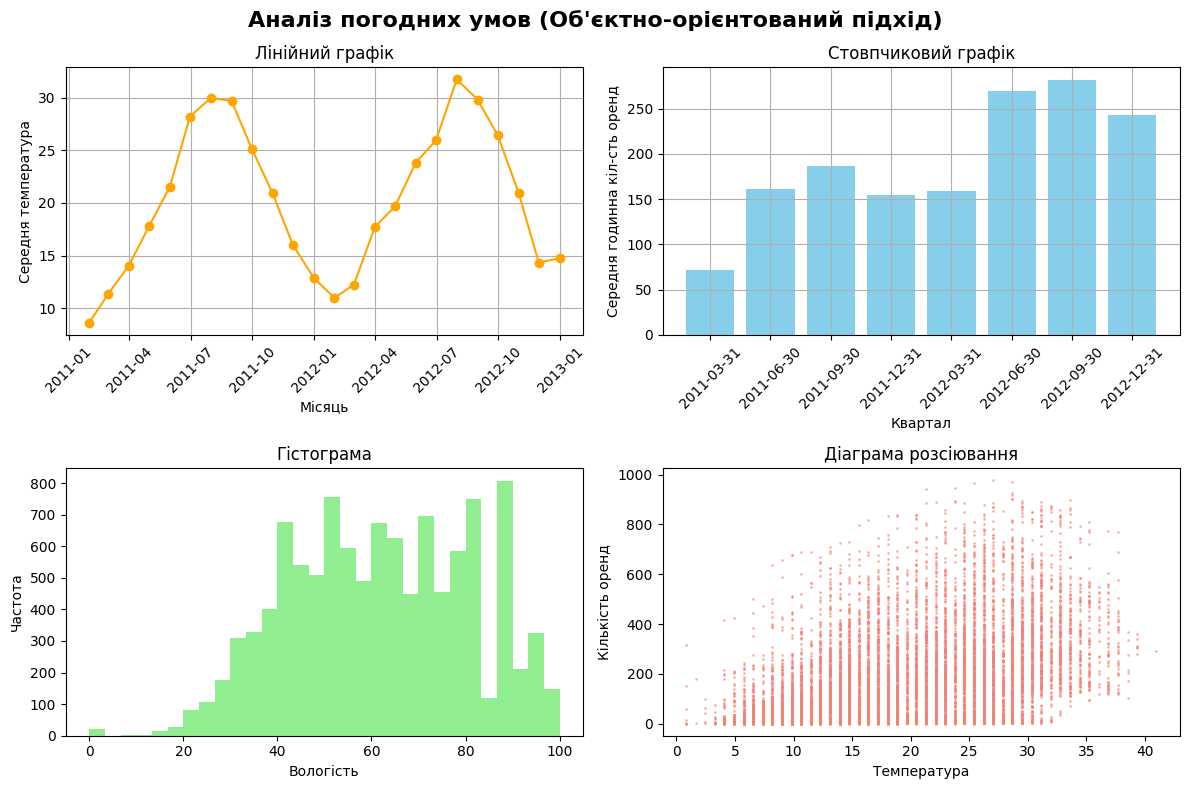

In [60]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# Лінійний графік
ax[0, 0].plot(temp_mean.index, temp_mean.values, marker='o', color='orange', linestyle='-')
ax[0, 0].set_title('Лінійний графік')
ax[0, 0].set_xlabel('Місяць')
ax[0, 0].set_ylabel('Середня температура')
ax[0, 0].grid(True)
ax[0, 0].tick_params(axis='x', rotation=45)

# Стовпчиковий графік
ax[0, 1].bar(rentals_mean.index.astype(str), rentals_mean.values, color='skyblue')
ax[0, 1].set_title('Стовпчиковий графік')
ax[0, 1].set_xlabel('Квартал')
ax[0, 1].set_ylabel('Середня годинна кіл-сть оренд')
ax[0, 1].grid(True)
ax[0, 1].tick_params(axis='x', rotation=45)

# Гістограма
ax[1, 0].hist(df['humidity'], bins=30, color='lightgreen')
ax[1, 0].set_title('Гістограма')
ax[1, 0].set_xlabel('Вологість')
ax[1, 0].set_ylabel('Частота')

# Діаграма розсіювання
ax[1, 1].scatter(df['temp'], df['count'], alpha=0.5, color='salmon', s=1)
ax[1, 1].set_title('Діаграма розсіювання')
ax[1, 1].set_xlabel('Температура')
ax[1, 1].set_ylabel('Кількість оренд')

fig.suptitle('Аналіз погодних умов (Об\'єктно-орієнтований підхід)', fontsize=16, fontweight='bold')
fig.tight_layout()
fig.savefig('my_dashboard_oo.png', dpi=300)

plt.show()


Підхід plt.subplot()  - ми малюємо графіки один за одним, даючи загальні команди для того віконця, які активні прямо зараз. Ми не маємо прямого доступу до попередніх графіків.
Підхід plt.subplots()- створює чітку структуру об'єктів — фігуру ( fig) та осі-віконця ( ax) . Ми отримуємо повний контроль над кожним графіком окремо за його «адресою»

## (Опціонально) Завдання 5: Тонкі налаштування форматування графіка

**Завдання:**
Подібно до прикладу, наведеного в лекції, створіть професійно оформлений графік помісячної динаміки оренди з максимальною кількістю деталей та налаштувань. Ваш графік має включати:

**Обов'язкові елементи:**
1. **Три лінії:** середнє, максимум, мінімум за місяцями
2. **Різні стилі ліній:** суцільна, пунктирна, крапкова + різні маркери
3. **Заливка області** між мінімумом та максимумом
4. **Дві анотації:** для найвищого та найнижчого середнього значення
5. **Горизонтальна лінія** середнього за весь рік
6. **Двошарова сітка:** основна та допоміжна
7. **Стилізована легенда** з тінню
8. **Текстовий блок** зі статистикою в кутку графіка
9. **Професійне оформлення:** заголовки, підписи осей з жирним шрифтом

**Результат:** Графік повинен виглядати як готова ілюстрація для бізнес-звіту або наукової публікації.

Приклад очікуваного результату.
![](https://drive.google.com/uc?id=1YoJByivzlqncEF2zbWu3EhGSZ7XRme8T)


**Питання для інтерпретації:**
1. Яка перевага додавання анотацій на графік?
2. Для чого використовується fill_between()?
3. Як текстовий блок допомагає в інтерпретації даних?

In [62]:
monthly_mean = df['count'].resample('ME').mean()
monthly_max = df['count'].resample('ME').max()
monthly_min = df['count'].resample('ME').min()

overall_mean = df['count'].mean()

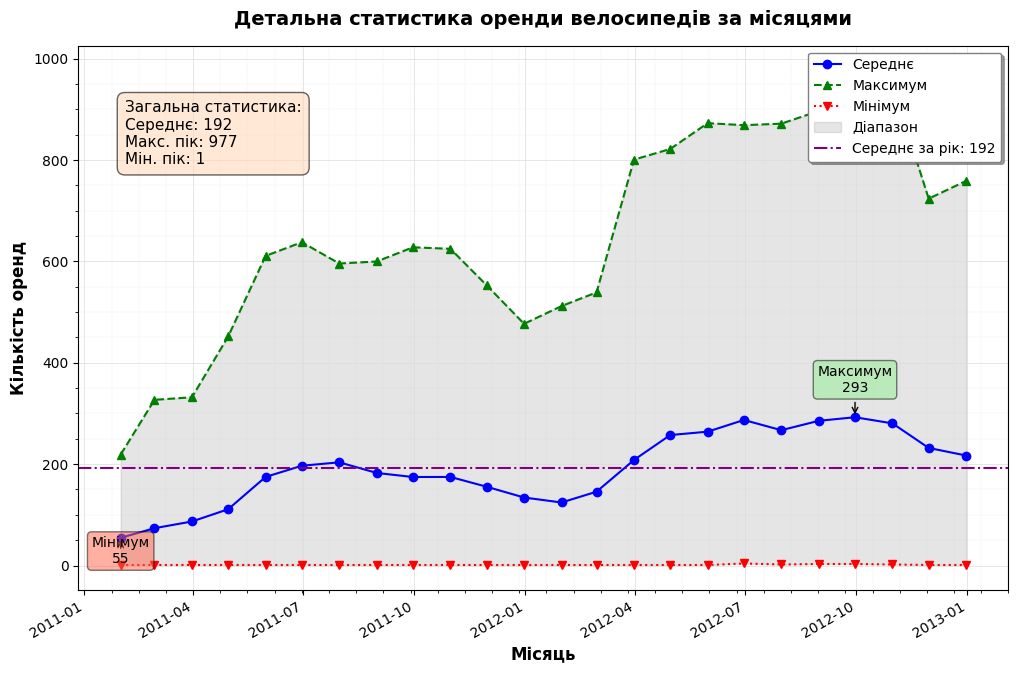

In [66]:
fig, ax = plt.subplots(figsize=(12, 8))

# 1. Три лінії: середня, максимум, мінімум з різними стилями (п.1, п.2)
ax.plot(monthly_mean.index, monthly_mean.values, label='Середнє', color='blue', linestyle='-', marker='o')
ax.plot(monthly_max.index, monthly_max.values, label='Максимум', color='green', linestyle='--', marker='^')
ax.plot(monthly_min.index, monthly_min.values, label='Мінімум', color='red', linestyle=':', marker='v')

# 2. Заливка області між мінімумом та максимумом (п.3)
ax.fill_between(monthly_mean.index, monthly_min.values, monthly_max.values, color='gray', alpha=0.2, label='Діапазон')

# 3. Горизонтальна лінія середнього за весь рік (п.5)
ax.axhline(overall_mean, color='purple', linestyle='-.', label=f'Середнє за рік: {overall_mean:.0f}')

# 4. Двошарова сітка: основна та допоміжна (п.6)
ax.grid(True, which='both', linestyle='-', linewidth=0.5, color='gainsboro')
ax.minorticks_on() # вмикаємо допоміжні поділки
ax.grid(True, which='minor', linestyle=':', linewidth=0.3, color='lightgray')

# 5. Дві анотації для найвищого та найнижчого СЕРЕДНЬОГО значення (п.4)
# Знаходимо дати та значення піків для СЕРЕДНЬОЇ лінії
max_mean_val = monthly_mean.max()
max_mean_date = monthly_mean.idxmax()

min_mean_val = monthly_mean.min()
min_mean_date = monthly_mean.idxmin()

# Анотація максимуму серединної лінії
ax.annotate(f'Максимум\n{max_mean_val:.0f}',
            xy=(max_mean_date, max_mean_val),
            xytext=(max_mean_date, max_mean_val + 50),
            arrowprops=dict(facecolor='black', arrowstyle='->'),
            bbox=dict(boxstyle='round,pad=0.3', fc='lightgreen', alpha=0.5),
            ha='center')

# Анотація мінімуму серединної лінії
ax.annotate(f'Мінімум\n{min_mean_val:.0f}',
            xy=(min_mean_date, min_mean_val),
            xytext=(min_mean_date, min_mean_val - 50),
            arrowprops=dict(facecolor='black', arrowstyle='->'),
            bbox=dict(boxstyle='round,pad=0.3', fc='tomato', alpha=0.5),
            ha='center')

# 6. Текстовий блок зі статистикою в кутку графіка (п.8)
stats_text = (
    f"Загальна статистика:\n"
    f"Середнє: {overall_mean:.0f}\n"
    f"Макс. пік: {monthly_max.max():.0f}\n"
    f"Мін. пік: {monthly_min.min():.0f}"
)
# Розміщуємо блок у верхньому лівому кутку (координати 0.05, 0.9)
ax.text(0.05, 0.9, stats_text, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', fc='peachpuff', alpha=0.6))

# 7. Професійне оформлення: жирні шрифти (п.9)
ax.set_title('Детальна статистика оренди велосипедів за місяцями', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Місяць', fontsize=12, fontweight='bold')
ax.set_ylabel('Кількість оренд', fontsize=12, fontweight='bold')

# 8. Стилізована легенда з тінню (п.7)
ax.legend(loc='upper right', shadow=True, facecolor='white', edgecolor='gray')

# Покращуємо відображення дат на осі X
fig.autofmt_xdate()

plt.show()
